# Semana 3 adaptada: análisis y modelos con Goodreads Books

Este notebook adapta el flujo de la semana 3 al conjunto de libros `pfaha/goodreads-books`:

1. Carga y limpieza de datos para explorar calificaciones, títulos, autores y páginas.
2. Crea tres **categorías derivadas** de calificación para practicar clasificación de texto. No son etiquetas originales del dataset.
3. Compara un baseline mayoritario con Naive Bayes y regresión logística usando `ClasificadorTexto`.
4. Entrena una regresión lineal para estimar la calificación a partir del número de páginas usando `RegresionLineal`.

La clasificación usa una muestra reproducible para mantener el tiempo y la memoria bajo control. No requiere ejecutar modelos externos de toxicidad. La primera carga del dataset sí requiere conexión a Hugging Face.

In [1]:
import sys
from datetime import datetime
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "hf_loader.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "hf_loader.py").exists():
    raise FileNotFoundError("No se encontró src/hf_loader.py. Abre el notebook desde el repositorio.")
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

from hf_loader import HFDatasetLoader
from clasificador_text import ClasificadorTexto
from regresion_lineal import RegresionLineal

SEMILLA = 42
MAX_FILAS_MODELOS = 30_000
CLASES = ["calificacion_baja", "calificacion_media", "calificacion_alta"]
CORTES_CALIFICACION = [-np.inf, 4.0, 4.25, np.inf]
COLORES = ["#e76f51", "#e9c46a", "#2a9d8f"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Proyecto: {ROOT}")

c:\Users\Nolberto Gomez\OneDrive\IU\AnaliticaDeDatos_MachineLearning\MachineLearning\RepoMachine_ProInteg3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Proyecto: C:\Users\Nolberto Gomez\OneDrive\IU\AnaliticaDeDatos_MachineLearning\MachineLearning\RepoMachine_ProInteg3


## 1. Cargar y preparar el dataset

Se usan los mismos campos principales que en la actividad de Goodreads. Se conserva el filtro de calificación mínima `3.5` de esa actividad. Para clasificación se eliminan duplicados exactos de texto antes de separar entrenamiento y prueba, reduciendo el riesgo de que el mismo título aparezca en ambos grupos.

In [2]:
loader = HFDatasetLoader(dataset_name="pfaha/goodreads-books", split="train")
df_original = loader.load()
print(f"Dataset original: {df_original.shape[0]:,} filas × {df_original.shape[1]} columnas")
print("Columnas disponibles:", df_original.columns.tolist())
df_original.head(3)

Dataset original: 500,000 filas × 24 columnas
Columnas disponibles: ['title', 'contributors', 'first_author', 'description', 'genres', 'series', 'format', 'pages', 'language', 'asin', 'isbn10', 'isbn13', 'publisher', 'publication_date', 'average_rating', 'ratings_count', 'reviews_count', 'work_id', 'catalog_guideline_violation', 'book_id', 'url', 'num_editions', 'has_more_editions', 'is_part_of_series']


,title,contributors,first_author,description,genres,series,format,pages,language,asin,...,average_rating,ratings_count,reviews_count,work_id,catalog_guideline_violation,book_id,url,num_editions,has_more_editions,is_part_of_series
0,La doctrina secreta. Vol I. Cosmogenesis (Cien...,"[{'name': 'Helena Petrovna Blavatsky', 'url': ...",Helena Petrovna Blavatsky,"Esta es una obra inteligente, original e instr...","[Occult, Spirituality, Nonfiction, Philosophy,...","[{'name': 'The Secret Doctrine', 'position': '...",Paperback,319.0,Spanish; Castilian,950171103X,...,4.16,255.0,22.0,44066165.0,False,7282453,https://www.goodreads.com/book/show/7282453,124.0,True,True
1,Clement Marot and the Inflections of Poetic Voice,"[{'name': 'Robert Griffin', 'url': 'https://ww...",Robert Griffin,This title is part of UC Press's Voices Revive...,[],[],Hardcover,NaN,English,0520025865,...,0.00,0.0,0.0,1320719.0,False,1331224,https://www.goodreads.com/book/show/1331224,2.0,True,False
2,How to Market Legal Services,"[{'name': 'Robert W Denney', 'url': 'https://w...",Robert W Denney,None,[],[],Hardcover,278.0,English,0442219806,...,0.00,0.0,0.0,3956063.0,False,3910678,https://www.goodreads.com/book/show/3910678,2.0,True,False


In [3]:
columnas_requeridas = {"title", "first_author", "pages", "average_rating"}
faltantes = columnas_requeridas.difference(df_original.columns)
if faltantes:
    raise KeyError(f"El dataset no contiene las columnas esperadas: {sorted(faltantes)}")

def a_texto(valor):
    if isinstance(valor, (list, tuple)):
        return ", ".join(str(parte) for parte in valor)
    return "" if pd.isna(valor) else str(valor)

filas_originales = len(df_original)
nulos_originales = int(df_original[["title", "first_author", "pages", "average_rating"]].isna().sum().sum())
df = df_original[["title", "first_author", "pages", "average_rating"]].copy()
df = df.rename(columns={
    "title": "titulo",
    "first_author": "autor",
    "pages": "paginas",
    "average_rating": "calificacion",
})
df["titulo"] = df["titulo"].map(a_texto).str.strip()
df["autor"] = df["autor"].map(a_texto).str.strip()
df["paginas"] = pd.to_numeric(df["paginas"], errors="coerce")
df["calificacion"] = pd.to_numeric(df["calificacion"], errors="coerce")
df = df.dropna(subset=["titulo", "autor", "calificacion"])
filas_sin_nulos_esenciales = len(df)
df = df[(df["titulo"] != "") & (df["calificacion"].between(3.5, 5.0))].copy()
filas_despues_filtro = len(df)
df["texto"] = (df["titulo"] + " " + df["autor"]).str.replace(r"\s+", " ", regex=True).str.strip()
filas_antes_duplicados = len(df)
df = df[df["texto"] != ""].drop_duplicates(subset="texto").reset_index(drop=True)
filas_sin_duplicados = len(df)
df["clase_calificacion"] = pd.cut(
    df["calificacion"], bins=CORTES_CALIFICACION, labels=CLASES, right=False
).astype(str)

auditoria_preprocesamiento = pd.DataFrame([
    {"etapa": "Dataset original", "filas": filas_originales,
     "cambio": f"{nulos_originales:,} valores nulos en las 4 columnas seleccionadas"},
    {"etapa": "Nulos esenciales eliminados", "filas": filas_sin_nulos_esenciales,
     "cambio": f"-{filas_originales - filas_sin_nulos_esenciales:,} filas sin título, autor o calificación"},
    {"etapa": "Filtro aplicado", "filas": filas_despues_filtro,
     "cambio": f"-{filas_sin_nulos_esenciales - filas_despues_filtro:,} filas; calificación entre 3.5 y 5"},
    {"etapa": "Texto duplicado eliminado", "filas": filas_sin_duplicados,
     "cambio": f"-{filas_antes_duplicados - filas_sin_duplicados:,} títulos+autor repetidos"},
])
display(auditoria_preprocesamiento)
print(f"Filas limpias y sin texto duplicado: {len(df):,}")
print("Faltantes por columna:\n", df[["titulo", "autor", "paginas", "calificacion"]].isna().sum())
df.head(3)

Filas limpias y sin texto duplicado: 261,614
Faltantes por columna:
 titulo              0
autor               0
paginas         20813
calificacion        0
dtype: int64


,titulo,autor,paginas,calificacion,texto,clase_calificacion
0,La doctrina secreta. Vol I. Cosmogenesis (Cien...,Helena Petrovna Blavatsky,319.0,4.16,La doctrina secreta. Vol I. Cosmogenesis (Cien...,calificacion_media
1,Personality and Intellectual Competence,Tomas Chamorro-Premuzic,214.0,3.88,Personality and Intellectual Competence Tomas ...,calificacion_baja
2,The Animals,Earle Rice Jr.,NaN,3.50,The Animals Earle Rice Jr.,calificacion_baja


## 2. Radiografía y distribución

La calificación es la variable numérica original. Para el ejercicio de clasificación se crean categorías con cortes fijos: menor que `4.0`, entre `4.0` y `4.25`, y desde `4.25`. Estas categorías son una transformación didáctica, no etiquetas proporcionadas por Goodreads ni por el profesor.

Dimensiones: (261614, 6)


,paginas,calificacion
count,2.408010e+05,261614.00
mean,2.918890e+03,4.08
std,1.304482e+06,0.40
min,0.000000e+00,3.50
25%,1.200000e+02,3.79
50%,2.240000e+02,4.00
75%,3.360000e+02,4.26
max,6.401284e+08,5.00


Textos duplicados restantes: 0


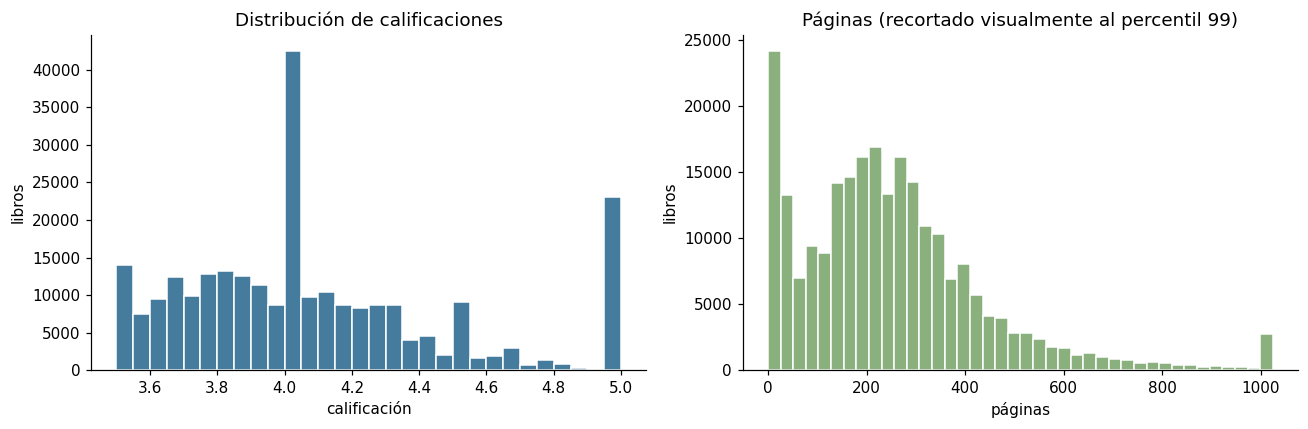

In [4]:
print("Dimensiones:", df.shape)
display(df[["paginas", "calificacion"]].describe().round(2))
print("Textos duplicados restantes:", df["texto"].duplicated().sum())

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].hist(df["calificacion"], bins=30, color="#457b9d", edgecolor="white")
ejes[0].set(title="Distribución de calificaciones", xlabel="calificación", ylabel="libros")
ejes[1].hist(df["paginas"].dropna().clip(upper=df["paginas"].quantile(0.99)),
             bins=40, color="#8ab17d", edgecolor="white")
ejes[1].set(title="Páginas (recortado visualmente al percentil 99)", xlabel="páginas", ylabel="libros")
plt.tight_layout()
plt.show()

,libros,%
clase_calificacion,,
calificacion_baja,112046,42.83
calificacion_media,79765,30.49
calificacion_alta,69803,26.68


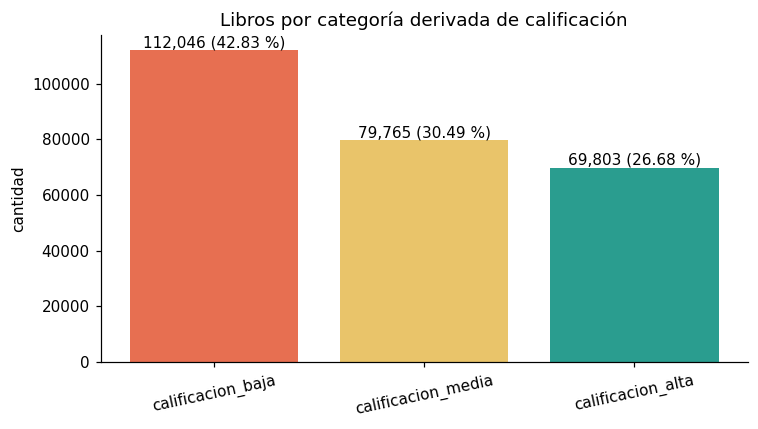

Baseline mayoritario: siempre 'calificacion_baja' → exactitud esperada 42.8%; recall de las otras categorías = 0.


In [5]:
conteo = df["clase_calificacion"].value_counts().reindex(CLASES, fill_value=0)
porcentaje = (conteo / conteo.sum() * 100).round(2)
display(pd.DataFrame({"libros": conteo, "%": porcentaje}))

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(conteo.index, conteo.values, color=COLORES)
ax.bar_label(barras, labels=[f"{n:,} ({p} %)" for n, p in zip(conteo, porcentaje)])
ax.set(title="Libros por categoría derivada de calificación", ylabel="cantidad")
ax.tick_params(axis="x", rotation=12)
plt.tight_layout()
plt.show()

mayoritaria = conteo.idxmax()
print(f"Baseline mayoritario: siempre '{mayoritaria}' → exactitud esperada {conteo.max() / conteo.sum():.1%}; "
      f"recall de las otras categorías = 0.")

## 3. Clasificar la categoría de calificación desde título y autor

Se limita el experimento a una muestra aleatoria reproducible de hasta 30 000 libros. TF-IDF convierte el texto en variables numéricas dispersas; Naive Bayes es un baseline habitual para texto y se compara con regresión logística, un clasificador lineal multicategoría. En logística se usa `class_weight="balanced"` para compensar el desbalance. Se prioriza F1 macro al comparar clases, sin dejar de revisar la exactitud frente al baseline mayoritario. TF-IDF y los modelos se ajustan solo con entrenamiento mediante `ClasificadorTexto`; las métricas se calculan en prueba. El texto de entrada es título + autor; no se incluye la calificación numérica.

In [6]:
if "clase_calificacion" not in df.columns:
    df["clase_calificacion"] = pd.cut(
        df["calificacion"], bins=CORTES_CALIFICACION, labels=CLASES, right=False
    ).astype(str)

n_modelo = min(MAX_FILAS_MODELOS, len(df))
df_clasificacion = df.sample(n=n_modelo, random_state=SEMILLA).reset_index(drop=True)
filas_clasificacion = len(df_clasificacion)
conteo_muestra = df_clasificacion["clase_calificacion"].value_counts()
if len(conteo_muestra) < 2 or (conteo_muestra < 2).any():
    raise ValueError(f"No hay suficientes ejemplos por clase para entrenar: {conteo_muestra.to_dict()}")
print(f"Muestra para clasificación: {len(df_clasificacion):,} libros")
print(conteo_muestra.reindex(CLASES, fill_value=0))

clasificador_nb = ClasificadorTexto(
    modelo=MultinomialNB(),
    columna_texto="texto",
    columna_objetivo="clase_calificacion",
    test_size=0.2,
    random_state=SEMILLA,
    ngram_range=(1, 2),
    max_features=20_000,
    directorio_modelos=ROOT / "modelos" / "libros",
)
resultado_nb = clasificador_nb.ejecutar(df_clasificacion)

Muestra para clasificación: 30,000 libros
clase_calificacion
calificacion_baja     12883
calificacion_media     9100
calificacion_alta      8017
Name: count, dtype: int64
[ejecutar][1/6] cargar_datos (MultinomialNB)
[ejecutar][2/6] preparar_datos
[preparar_datos] 30000 textos válidos; 0 filas eliminadas; clases: {'calificacion_baja': 12883, 'calificacion_media': 9100, 'calificacion_alta': 8017}.
[ejecutar][3/6] dividir_datos
[dividir_datos] stratify=y; entrenamiento=24000; prueba=6000; random_state=42.
[ejecutar][4/6] construir_modelo
[construir_modelo] TfidfVectorizer(1, 2) -> MultinomialNB
[ejecutar][5/6] entrenar
[entrenar] 24000 textos; modelo guardado en C:\Users\Nolberto Gomez\OneDrive\IU\AnaliticaDeDatos_MachineLearning\MachineLearning\RepoMachine_ProInteg3\modelos\libros\20261024_195424_798867_MultinomialNB.pkl
[ejecutar][6/6] evaluar
[evaluar] exactitud=0.4408; F1 macro=0.3387; F1 ponderado=0.3755
                    precision    recall  f1-score   support

 calificacion_alta 

In [7]:
clasificador_lr = ClasificadorTexto(
    modelo=LogisticRegression(class_weight="balanced", max_iter=400),
    columna_texto="texto",
    columna_objetivo="clase_calificacion",
    test_size=0.2,
    random_state=SEMILLA,
    ngram_range=(1, 2),
    max_features=20_000,
    directorio_modelos=ROOT / "modelos" / "libros",
)
resultado_lr = clasificador_lr.ejecutar(df_clasificacion)

comparacion = pd.DataFrame({
    "exactitud": [resultado_nb["metricas"]["exactitud"], resultado_lr["metricas"]["exactitud"]],
    "F1 macro": [resultado_nb["metricas"]["f1_macro"], resultado_lr["metricas"]["f1_macro"]],
    "F1 ponderado": [resultado_nb["metricas"]["f1_ponderado"], resultado_lr["metricas"]["f1_ponderado"]],
}, index=["Naive Bayes", "Regresión logística"])
display(comparacion.round(4))

tabla_clases_lr = clasificador_lr.metricas["por_clase"]
clase_mejor_recall = tabla_clases_lr["recall"].idxmax()
clase_peor_recall = tabla_clases_lr["recall"].idxmin()
print(f"Regresión logística: mejor recall = {clase_mejor_recall} ({tabla_clases_lr.loc[clase_mejor_recall, 'recall']:.3f}); "
      f"menor recall = {clase_peor_recall} ({tabla_clases_lr.loc[clase_peor_recall, 'recall']:.3f}).")
print(f"Se prioriza F1 macro para comparar las clases: logística={resultado_lr['metricas']['f1_macro']:.3f}; "
      f"Naive Bayes={resultado_nb['metricas']['f1_macro']:.3f}; baseline de exactitud={conteo_muestra.max() / filas_clasificacion:.3f}.")
print("La exactitud se compara con el baseline mayoritario; F1 macro da el mismo peso a cada clase, "
      "por lo que ayuda a evaluar el desbalance.")

[ejecutar][1/6] cargar_datos (LogisticRegression)
[ejecutar][2/6] preparar_datos
[preparar_datos] 30000 textos válidos; 0 filas eliminadas; clases: {'calificacion_baja': 12883, 'calificacion_media': 9100, 'calificacion_alta': 8017}.
[ejecutar][3/6] dividir_datos
[dividir_datos] stratify=y; entrenamiento=24000; prueba=6000; random_state=42.
[ejecutar][4/6] construir_modelo
[construir_modelo] TfidfVectorizer(1, 2) -> LogisticRegression
[ejecutar][5/6] entrenar
[entrenar] 24000 textos; modelo guardado en C:\Users\Nolberto Gomez\OneDrive\IU\AnaliticaDeDatos_MachineLearning\MachineLearning\RepoMachine_ProInteg3\modelos\libros\20261024_195428_696258_LogisticRegression.pkl
[ejecutar][6/6] evaluar
[evaluar] exactitud=0.4198; F1 macro=0.4058; F1 ponderado=0.4213
                    precision    recall  f1-score   support

 calificacion_alta     0.3442    0.3899    0.3656      1603
 calificacion_baja     0.5317    0.5041    0.5175      2577
calificacion_media     0.3418    0.3269    0.3342      

,exactitud,F1 macro,F1 ponderado
Naive Bayes,0.4408,0.3387,0.3755
Regresión logística,0.4198,0.4058,0.4213


### Matrices de confusión y términos asociados a cada categoría

Las matrices permiten ver qué categorías se confunden. Los términos mostrados son los que más favorecen cada clase según los pesos aprendidos por el modelo; son asociaciones del modelo, no explicaciones causales.

C:\Users\Nolberto Gomez\AppData\Local\Temp\ipykernel_23232\4075889437.py:13: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


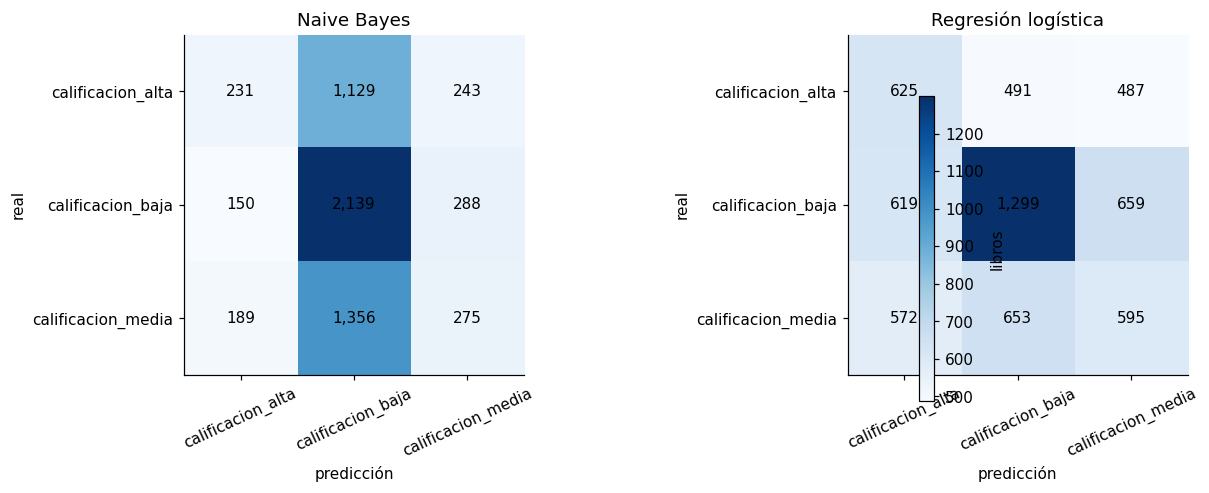

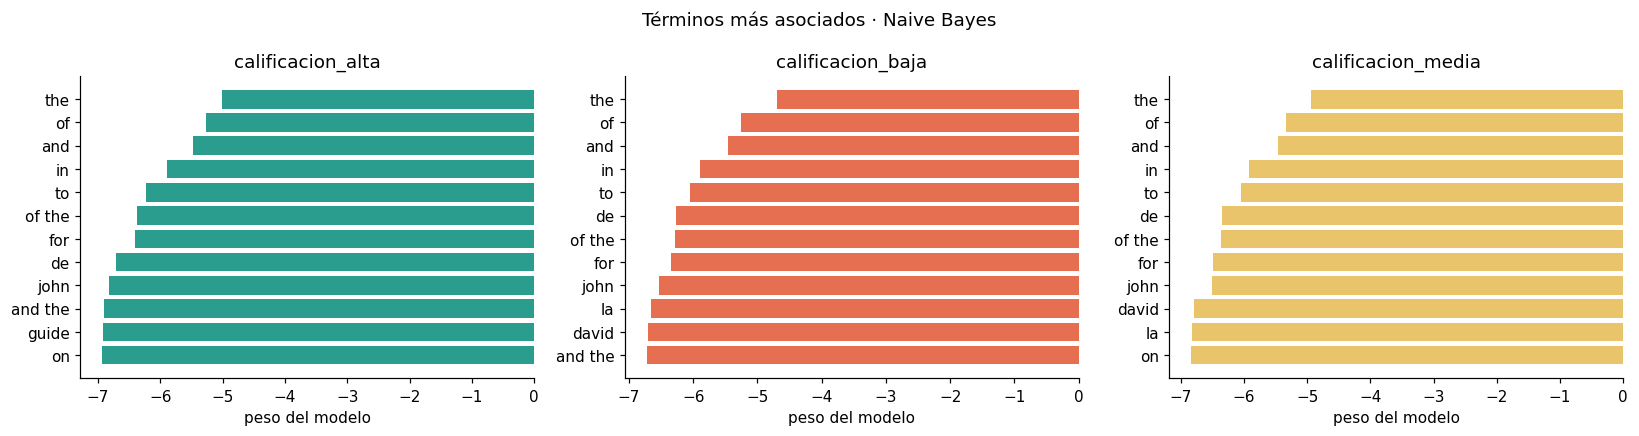

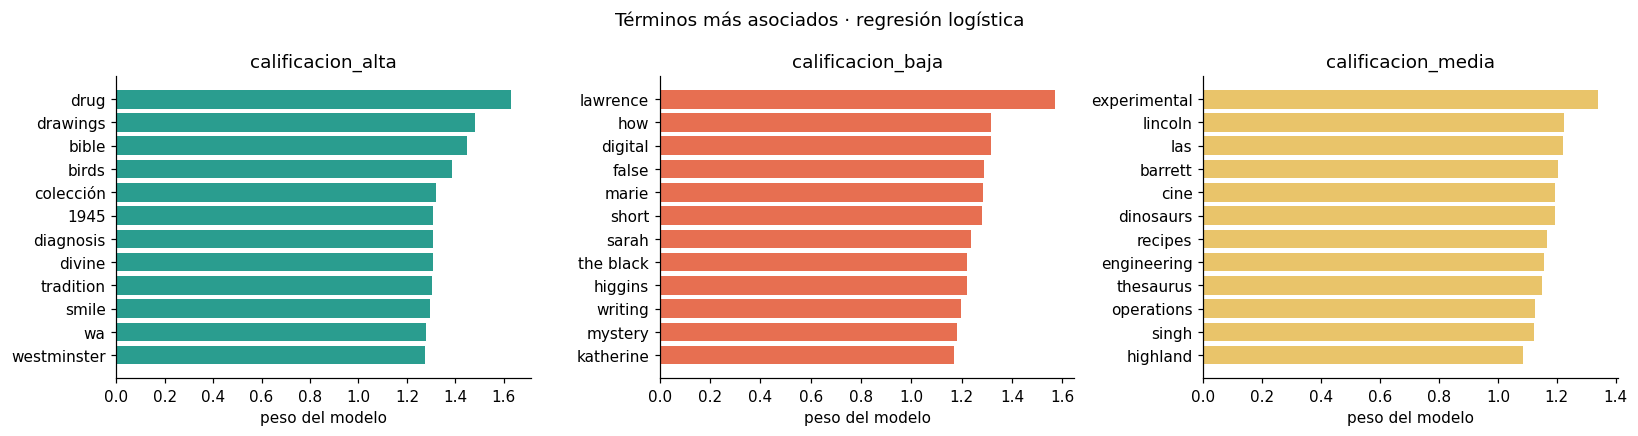

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, modelo, nombre in zip(ejes, [clasificador_nb, clasificador_lr], ["Naive Bayes", "Regresión logística"]):
    matriz = modelo.metricas["matriz"]
    imagen = ax.imshow(matriz.to_numpy(), cmap="Blues")
    ax.set(title=nombre, xlabel="predicción", ylabel="real",
           xticks=range(len(matriz.columns)), xticklabels=[c.replace("pred ", "") for c in matriz.columns],
           yticks=range(len(matriz.index)), yticklabels=[c.replace("real ", "") for c in matriz.index])
    ax.tick_params(axis="x", rotation=25)
    for fila in range(len(CLASES)):
        for columna in range(len(CLASES)):
            ax.text(columna, fila, f"{matriz.iloc[fila, columna]:,}", ha="center", va="center")
fig.colorbar(imagen, ax=ejes, shrink=0.8, label="libros")
plt.tight_layout()
plt.show()

def graficar_terminos(modelo, titulo):
    vectorizador = modelo.pipeline.named_steps["tfidf"]
    estimador = modelo.pipeline.named_steps["modelo"]
    terminos = vectorizador.get_feature_names_out()
    pesos = estimador.feature_log_prob_ if hasattr(estimador, "feature_log_prob_") else estimador.coef_
    fig, ejes = plt.subplots(1, len(CLASES), figsize=(15, 4))
    for indice, (ax, clase) in enumerate(zip(ejes, estimador.classes_)):
        top = np.argsort(pesos[indice])[-12:]
        ax.barh(terminos[top], pesos[indice][top], color=COLORES[CLASES.index(clase)])
        ax.set(title=clase, xlabel="peso del modelo")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

graficar_terminos(clasificador_nb, "Términos más asociados · Naive Bayes")
graficar_terminos(clasificador_lr, "Términos más asociados · regresión logística")

In [9]:
errores = pd.DataFrame({
    "titulo_y_autor": clasificador_lr.X_test.to_numpy(),
    "real": clasificador_lr.y_test.to_numpy(),
    "predicho": clasificador_lr.predicciones,
})
errores = errores[errores["real"] != errores["predicho"]]
print(f"Errores de regresión logística: {len(errores):,}")
display(errores.head(12))

Errores de regresión logística: 3,481


,titulo_y_autor,real,predicho
1,Zebras Emilie U. Lepthien,calificacion_alta,calificacion_media
2,Walls of Fear Kathryn Cramer,calificacion_baja,calificacion_media
5,Probability and Statistics for Engineers Richa...,calificacion_media,calificacion_baja
6,Fabrica Files 07-12 Electa,calificacion_media,calificacion_alta
7,Agility Training for You and Your Dog: From Ba...,calificacion_baja,calificacion_alta
9,Argument: A Prentice Hall Pocket Reader Christ...,calificacion_alta,calificacion_baja
10,What If ... ?: Your Beliefs Shape Your Life Fr...,calificacion_alta,calificacion_baja
12,Following the River: A Vision for Corporate Wo...,calificacion_alta,calificacion_baja
14,Fish Eyes: A Book You Can Count On Lois Ehlert,calificacion_baja,calificacion_alta
18,The Embrace of Spirit: A Woman's Guide to Mind...,calificacion_baja,calificacion_media


## 4. Regresión lineal: estimar calificación usando páginas

Esta es una pregunta distinta a la clasificación: el objetivo es una calificación numérica. Se usa `paginas` como predictor porque es una variable numérica disponible y permite interpretar directamente el cambio estimado por página; se trata de un modelo de referencia sencillo, no de una explicación completa de las calificaciones. Se excluyen filas sin páginas, páginas no positivas y valores extremos por encima del percentil 99 para que registros anómalos no dominen el ajuste. No se escala porque hay un solo predictor y se desea conservar la unidad de páginas. `RegresionLineal` divide en entrenamiento/prueba, entrena con los valores de entrenamiento y reporta MAE, RMSE y R².

In [10]:
filas_antes_filtro_paginas = len(df)
paginas_validas = df["paginas"].dropna()
limite_paginas = paginas_validas.quantile(0.99)
df_regresion = df[
    df["paginas"].between(1, limite_paginas)
].copy()
filas_regresion_validas = len(df_regresion)
df_regresion = df_regresion.sample(
    n=min(MAX_FILAS_MODELOS, len(df_regresion)), random_state=SEMILLA
).reset_index(drop=True)
filas_regresion = len(df_regresion)
print(f"Límite de páginas (percentil 99): {limite_paginas:.0f}")
print(f"Filtro de páginas: {filas_regresion_validas:,} de {filas_antes_filtro_paginas:,} filas conservadas "
      f"(páginas > 0 y hasta el percentil 99).")
print(f"Muestra para regresión: {len(df_regresion):,} libros")

regresion = RegresionLineal(
    feature_column="paginas",
    target_column="calificacion",
    test_size=0.2,
    random_state=SEMILLA,
)
resultado_regresion = regresion.ejecutar(df_regresion)
display(pd.Series(resultado_regresion["metricas"], name="valor").to_frame().round(4))
print("Intercepto:", regresion.modelo.intercept_)
print("Coeficiente para páginas:", regresion.modelo.coef_[0])

Límite de páginas (percentil 99): 1024
Muestra para regresión: 30,000 libros
[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['paginas'], y='calificacion'; 30000 filas válidas; 0 filas eliminadas; X=(30000, 1), y=(30000,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=24000 filas (24000, 1); prueba=6000 filas (6000, 1).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ejecutar][3/6] Iniciando entrenar.
[entrenar] modelo ajustado con 24000 filas y 1 características.
[entrenar] modelo guardado en: entrenamiento\20261024_195431_419236_modelo.pkl
[ejecutar][4/6] Iniciando predecir.
[predecir] modelo cargado desde entrenamiento\20261024_195431_419236_modelo.pkl; 6000 predicciones generadas.
[ejecutar][5/6] Iniciando obtener_parametros.
[obtener_parametros] modelo cargado desde entrenamiento\20261024_195431_419236_modelo.pkl; w=-6.609992787725645e-05; b=4

,valor
mae,0.3163
rmse,0.4087
r2,-0.0010


Intercepto: 4.0896907493463575
Coeficiente para páginas: -6.609992787725645e-05


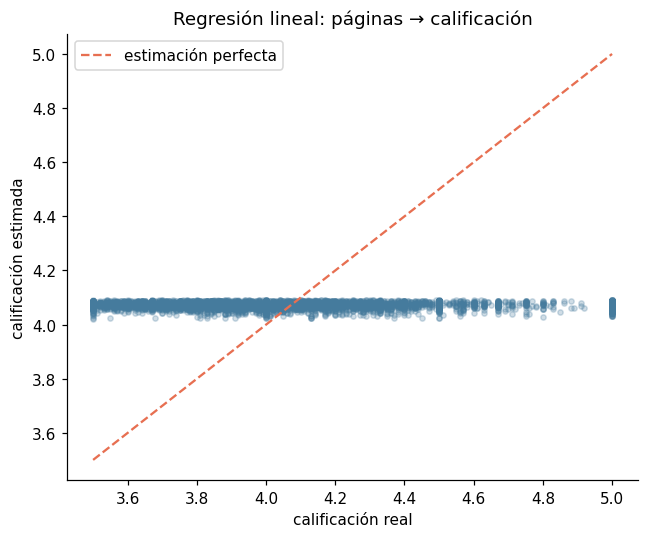

MAE: 0.3163
RMSE: 0.4087
R²: -0.001


In [11]:
y_real = resultado_regresion["y_test"].to_numpy()
y_estimado = resultado_regresion["predicciones"]
limite = [min(y_real.min(), y_estimado.min()), max(y_real.max(), y_estimado.max())]

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_real, y_estimado, alpha=0.25, s=12, color="#457b9d")
ax.plot(limite, limite, color="#e76f51", linestyle="--", label="estimación perfecta")
ax.set(xlabel="calificación real", ylabel="calificación estimada",
       title="Regresión lineal: páginas → calificación")
ax.legend()
plt.tight_layout()
plt.show()

print("MAE:", round(resultado_regresion["metricas"]["mae"], 4))
print("RMSE:", round(resultado_regresion["metricas"]["rmse"], 4))
print("R²:", round(resultado_regresion["metricas"]["r2"], 4))

coef_paginas = float(regresion.modelo.coef_[0])
intercepto = float(regresion.modelo.intercept_)
mae = resultado_regresion["metricas"]["mae"]
rmse = resultado_regresion["metricas"]["rmse"]
r2 = resultado_regresion["metricas"]["r2"]
interpretacion_r2 = (
    f"El modelo explica aproximadamente {max(0.0, r2) * 100:.1f}% de la variación de la calificación en prueba."
    if r2 >= 0 else
    "R² negativo: en esta partición el modelo predice peor que usar la media de las calificaciones de entrenamiento."
)
print(f"Interpretación: por cada página adicional, la predicción cambia {coef_paginas:.6f} estrellas en promedio; "
      f"el intercepto ({intercepto:.3f}) es la predicción matemática para 0 páginas, fuera del rango usado.")
print(f"MAE={mae:.3f} significa un error absoluto medio de {mae:.3f} estrellas; RMSE={rmse:.3f} penaliza más los errores grandes.")
print(interpretacion_r2)
print("Limitación: páginas por sí sola difícilmente captura género, autor, popularidad o calidad percibida.")

metricas_nb = resultado_nb["metricas"]
metricas_lr = resultado_lr["metricas"]
baseline_clase = conteo_muestra.idxmax()
baseline_exactitud = float(conteo_muestra.max() / filas_clasificacion)
precision_mejor = float(tabla_clases_lr.loc[clase_mejor_recall, "precision"])
f1_mejor = float(tabla_clases_lr.loc[clase_mejor_recall, "f1"])
interpretacion_clasificacion = (
    f"La regresión logística tiene exactitud {metricas_lr['exactitud']:.3f} frente a {baseline_exactitud:.3f} del baseline. "
    f"Se prioriza F1 macro ({metricas_lr['f1_macro']:.3f} frente a {metricas_nb['f1_macro']:.3f} de Naive Bayes), aunque la exactitud se compara con el baseline. "
    f"Su mejor recall es {clase_mejor_recall} ({tabla_clases_lr.loc[clase_mejor_recall, 'recall']:.3f}) y el menor es "
    f"{clase_peor_recall} ({tabla_clases_lr.loc[clase_peor_recall, 'recall']:.3f}); revisar la matriz para observar confusiones."
)

lineas_reporte = [
    "RESUMEN AUTOMÁTICO DE MODELOS — GOODREADS BOOKS",
    "=" * 58,
    f"Fecha de ejecución: {datetime.now().astimezone().isoformat(timespec='seconds')}",
    "Dataset: pfaha/goodreads-books, partición train de Hugging Face.",
    f"Filas originales: {filas_originales:,}; filas limpias sin texto duplicado: {len(df):,}.",
    "",
    "PREPROCESAMIENTO",
    auditoria_preprocesamiento.to_string(index=False),
    "- Conversión de páginas/calificación a numérico: valores no convertibles pasan a nulo.",
    "- Título y autor vacíos/nulos se excluyen; calificación se restringe a [3.5, 5.0] para seguir el filtro de la actividad base.",
    "- Se elimina texto duplicado (título + autor) antes de muestrear para reducir duplicados entre train y test.",
    "- Las categorías baja (<4.0), media ([4.0, 4.25)) y alta (>=4.25) se derivan de average_rating; no son etiquetas originales.",
    "- El vocabulario TF-IDF se ajusta solo en entrenamiento. La regresión usa páginas válidas >0 hasta percentil 99; no se escala.",
    "",
    "REGRESIÓN LINEAL",
    "Pregunta: ¿se puede estimar la calificación promedio de un libro a partir de sus páginas?",
    "Predictoras: paginas. Objetivo: calificacion (estrellas).",
    "Algoritmo: sklearn LinearRegression (intercepto incluido por defecto).",
    f"Configuración: muestra={filas_regresion:,}; test_size=0.20; random_state={SEMILLA}; "
    f"entrenamiento={len(resultado_regresion['X_train']):,}; prueba={len(resultado_regresion['X_test']):,}; "
    f"filtro páginas 1..P99 ({limite_paginas:.0f}); máximo {MAX_FILAS_MODELOS:,} filas.",
    f"Evidencia páginas: {filas_regresion_validas:,} filas válidas de {filas_antes_filtro_paginas:,} antes del filtro; "
    f"muestra final={filas_regresion:,}.",
    f"Coeficiente páginas={coef_paginas:.8f}; intercepto={intercepto:.6f}.",
    f"MAE={mae:.4f} estrellas; RMSE={rmse:.4f} estrellas; R2={r2:.4f}.",
    f"Interpretación: por página adicional, el modelo cambia su predicción en {coef_paginas:.6f} estrellas; "
    f"MAE indica un error absoluto medio de {mae:.3f} estrellas. {interpretacion_r2}",
    "Limitaciones: una sola característica no representa género, autor, antigüedad ni popularidad; el intercepto a 0 páginas no tiene interpretación práctica.",
    "",
    "CLASIFICACIÓN DE TEXTO",
    "Objetivo: clasificar la categoría derivada de calificación desde el texto título + autor.",
    f"Muestra={filas_clasificacion:,}; clases: {conteo_muestra.to_dict()}.",
    f"División: test_size=0.20; random_state={SEMILLA}; entrenamiento={len(clasificador_lr.X_train):,}; prueba={len(clasificador_lr.X_test):,}.",
    "Modelo reportado: LogisticRegression(class_weight='balanced', max_iter=400), solver='lbfgs', C=1.0; "
    "TfidfVectorizer(ngram_range=(1, 2), max_features=20000).",
    f"Baseline mayoritario: {baseline_clase}, exactitud={baseline_exactitud:.4f}; recall en otras clases=0.",
    f"Naive Bayes comparativo: exactitud={metricas_nb['exactitud']:.4f}, F1 macro={metricas_nb['f1_macro']:.4f}, "
    f"F1 ponderado={metricas_nb['f1_ponderado']:.4f}.",
    f"Regresión logística: exactitud={metricas_lr['exactitud']:.4f}, F1 macro={metricas_lr['f1_macro']:.4f}, "
    f"F1 ponderado={metricas_lr['f1_ponderado']:.4f}.",
    "Criterio de selección para interpretación: F1 macro pondera igual las tres clases; en esta corrida supera al Naive Bayes, aunque la exactitud de ambos se contrasta también con el baseline.",
    "Métricas por clase (precision/recall/F1/casos):",
    tabla_clases_lr.to_string(float_format=lambda valor: f"{valor:.4f}"),
    "Matriz de confusión (filas=real, columnas=predicción):",
    clasificador_lr.metricas["matriz"].to_string(),
    f"Interpretación: {interpretacion_clasificacion}",
    f"Mejor recall: {clase_mejor_recall} (precision={precision_mejor:.3f}, F1={f1_mejor:.3f}); "
    f"menor recall: {clase_peor_recall}.",
    "Limitaciones: categorías de rating son cortes didácticos, no etiquetas originales; título/autor contienen poca señal directa de rating; los resultados dependen de la muestra y de la partición.",
    "",
    "Conclusión: consultar MAE/R2 para la regresión y F1 macro/matriz para las clases minoritarias; "
    "no interpretar asociaciones como causalidad.",
]
contenido_reporte = "\n".join(lineas_reporte) + "\n"
ruta_reporte = ROOT / "reportes" / "resumen_modelos_libros.txt"
ruta_reporte.parent.mkdir(parents=True, exist_ok=True)
ruta_reporte.write_text(contenido_reporte, encoding="utf-8")
print(f"\nResumen generado desde esta ejecución: {ruta_reporte}")
print(contenido_reporte)